# BONUS - INTERPRETABILITY

In [15]:
import torch, math
import numpy as np
import matplotlib.pyplot as plt

def show_feature_grid(tensor, title, max_ch=16):
    t = tensor[0]  
    C = min(max_ch, t.shape[0])
    cols, rows = 4, math.ceil(C/4)
    plt.figure(figsize=(cols*2.2, rows*2.2))
    for i in range(C):
        plt.subplot(rows, cols, i+1)
        plt.imshow(t[i], cmap="gray")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [16]:
def register_hooks(layers_dict):
    acts = {}
    handles = []
    def make_hook(name):
        def hook(module, inputs, output):
            acts[name] = output.detach().cpu()
        return hook
    for name, module in layers_dict.items():
        h = module.register_forward_hook(make_hook(name))
        handles.append(h)
    return acts, handles

def remove_hooks(handles):
    for h in handles:
        h.remove()

## CONVOLUTIONAL LAYER OUTPUTS

In [17]:
mdl = model_best if 'model_best' in globals() else model
mdl.eval()

conv_layers = {
    "early_conv1_out":  mdl.conv1,
    "mid_layer2b3_conv2_out": mdl.layer2[2].conv2,
    "late_layer4b3_conv2_out": mdl.layer4[2].conv2,
}

conv_acts, conv_handles = register_hooks(conv_layers)

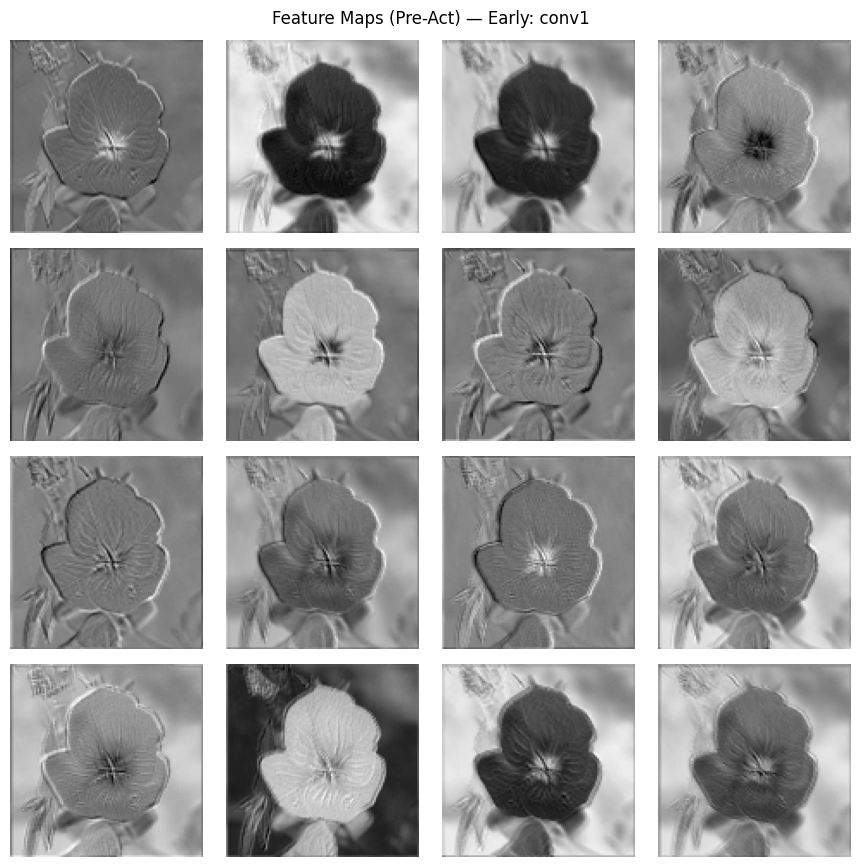

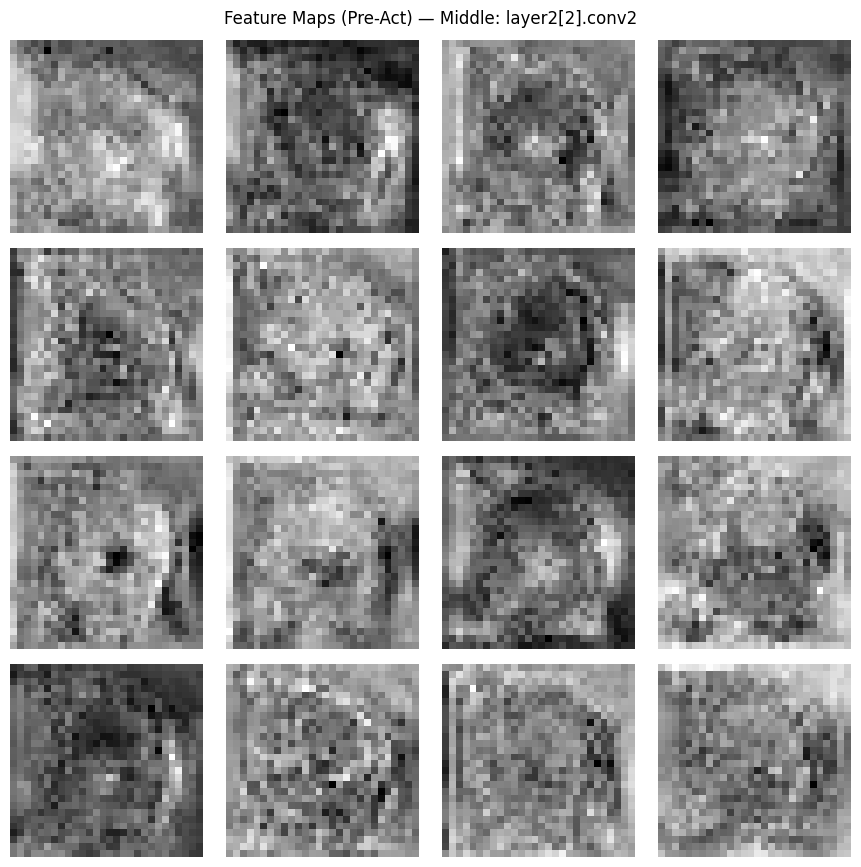

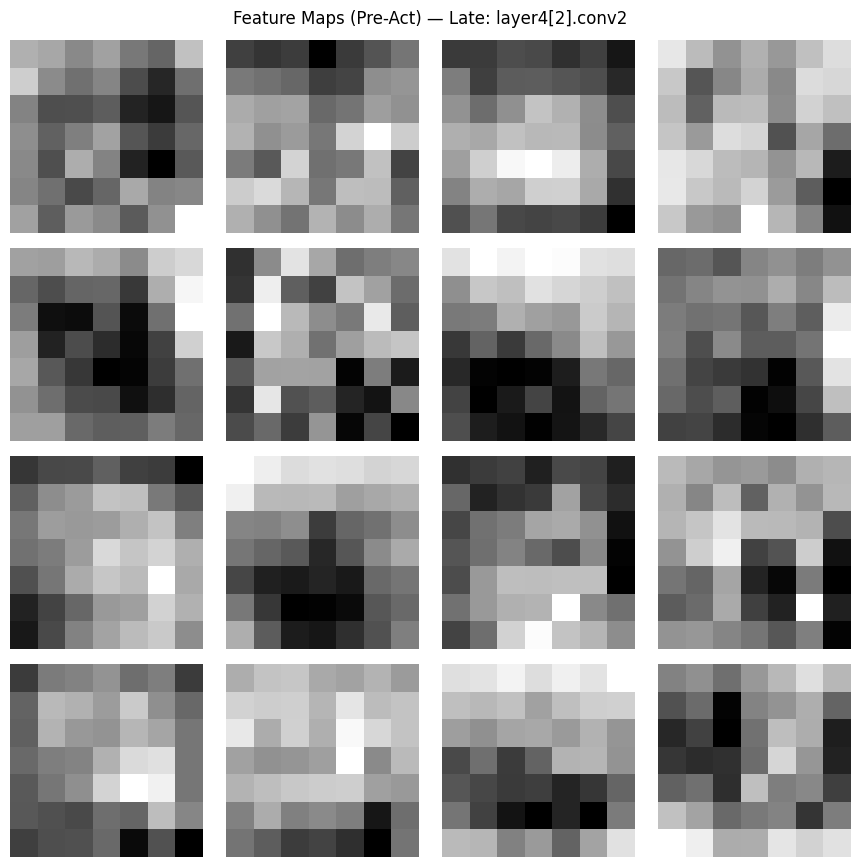

In [20]:
xb, yb = next(iter(test_dl))
_ = mdl(xb[:1].to(device))

remove_hooks(conv_handles)

show_feature_grid(conv_acts["early_conv1_out"],        "Feature Maps (Pre-Act) — Early: conv1")
show_feature_grid(conv_acts["mid_layer2b3_conv2_out"], "Feature Maps (Pre-Act) — Middle: layer2[2].conv2")
show_feature_grid(conv_acts["late_layer4b3_conv2_out"],"Feature Maps (Pre-Act) — Late: layer4[2].conv2")

**Analysis:**
• Early conv maps highlight simple edges and color blobs.
• Middle-layer maps start to capture textures and petal patterns.

## ACTIVATION LAYER OUTPUTS

In [21]:
act_layers = {"early_relu_out":  mdl.relu,"mid_block_relu":  mdl.layer2[2].relu,"late_block_relu": mdl.layer4[2].relu,}
post_acts, post_handles = register_hooks(act_layers)
_ = mdl(xb[:1].to(device))
remove_hooks(post_handles)


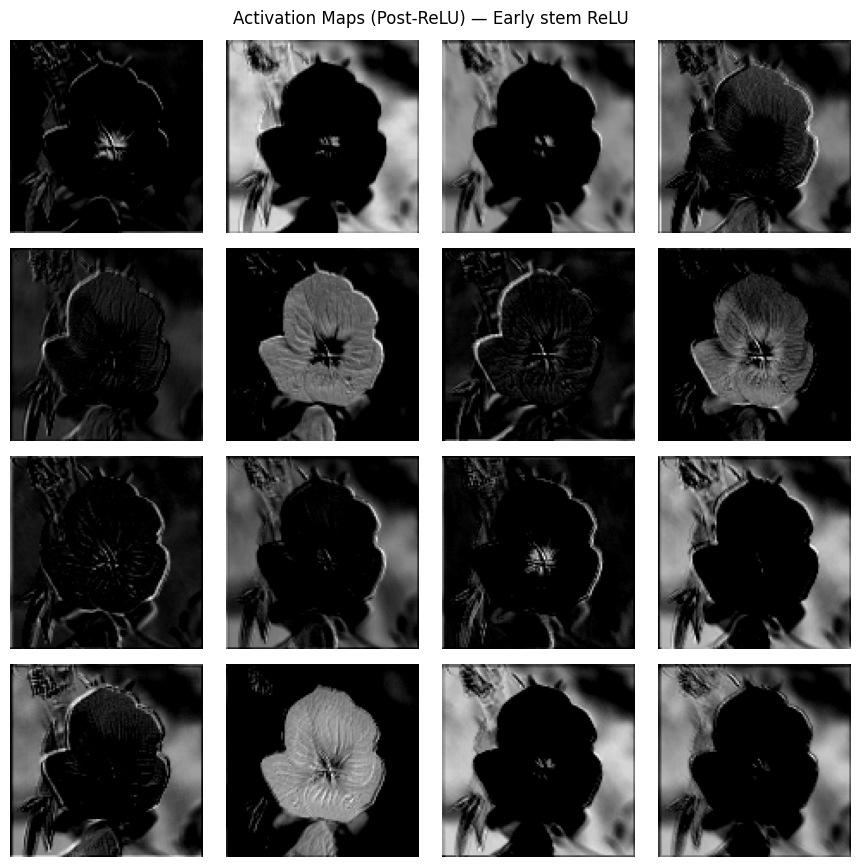

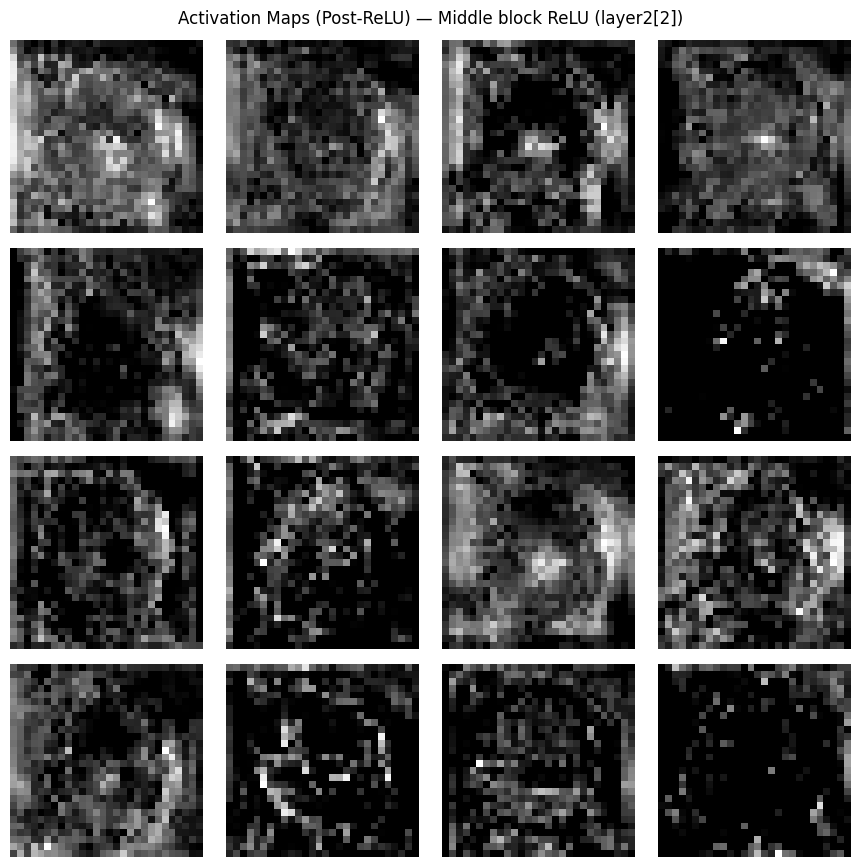

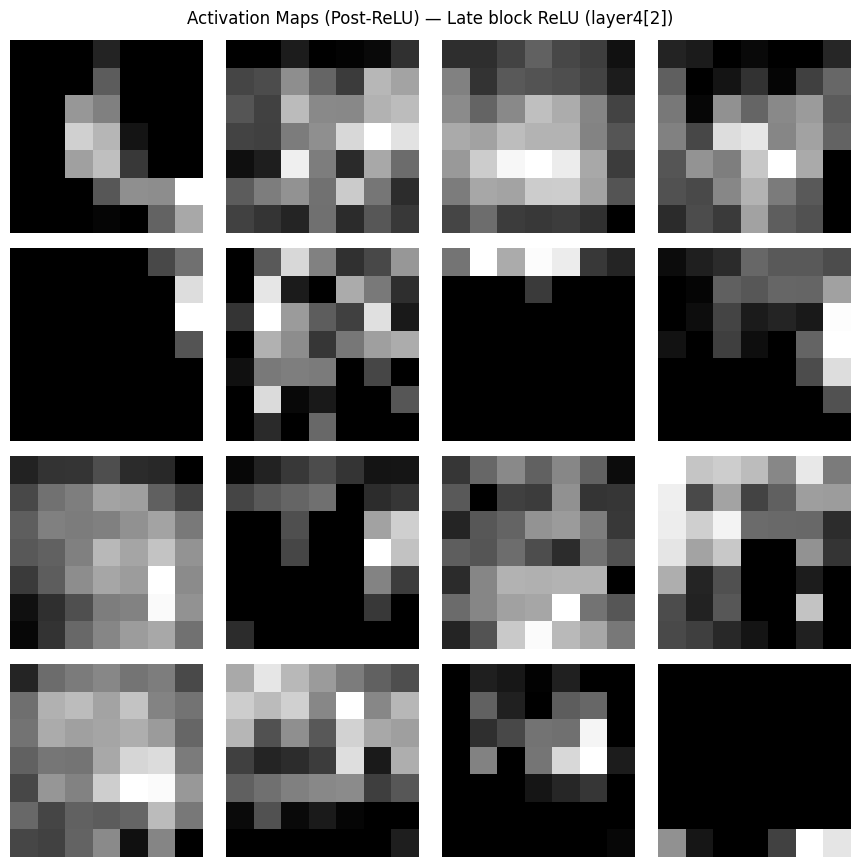

In [22]:
show_feature_grid(post_acts["early_relu_out"], "Activation Maps (Post-ReLU) — Early stem ReLU")
show_feature_grid(post_acts["mid_block_relu"], "Activation Maps (Post-ReLU) — Middle block ReLU (layer2[2])")
show_feature_grid(post_acts["late_block_relu"],"Activation Maps (Post-ReLU) — Late block ReLU (layer4[2])")

**Analysisv:**
• Post-ReLU maps suppress negative responses and emphasize features that the network believes are useful.
• Early ReLU maps mostly strengthen strong edges and color contrasts.

## WEIGHT VISUALIZATION

In [23]:
w = mdl.conv1.weight.data.clone().cpu()

In [24]:
w_flat = w.view(w.size(0), -1)
w_min = w_flat.min(dim=1)[0].view(-1, 1, 1, 1)
w_max = w_flat.max(dim=1)[0].view(-1, 1, 1, 1)
w_norm = (w - w_min) / (w_max - w_min + 1e-8)

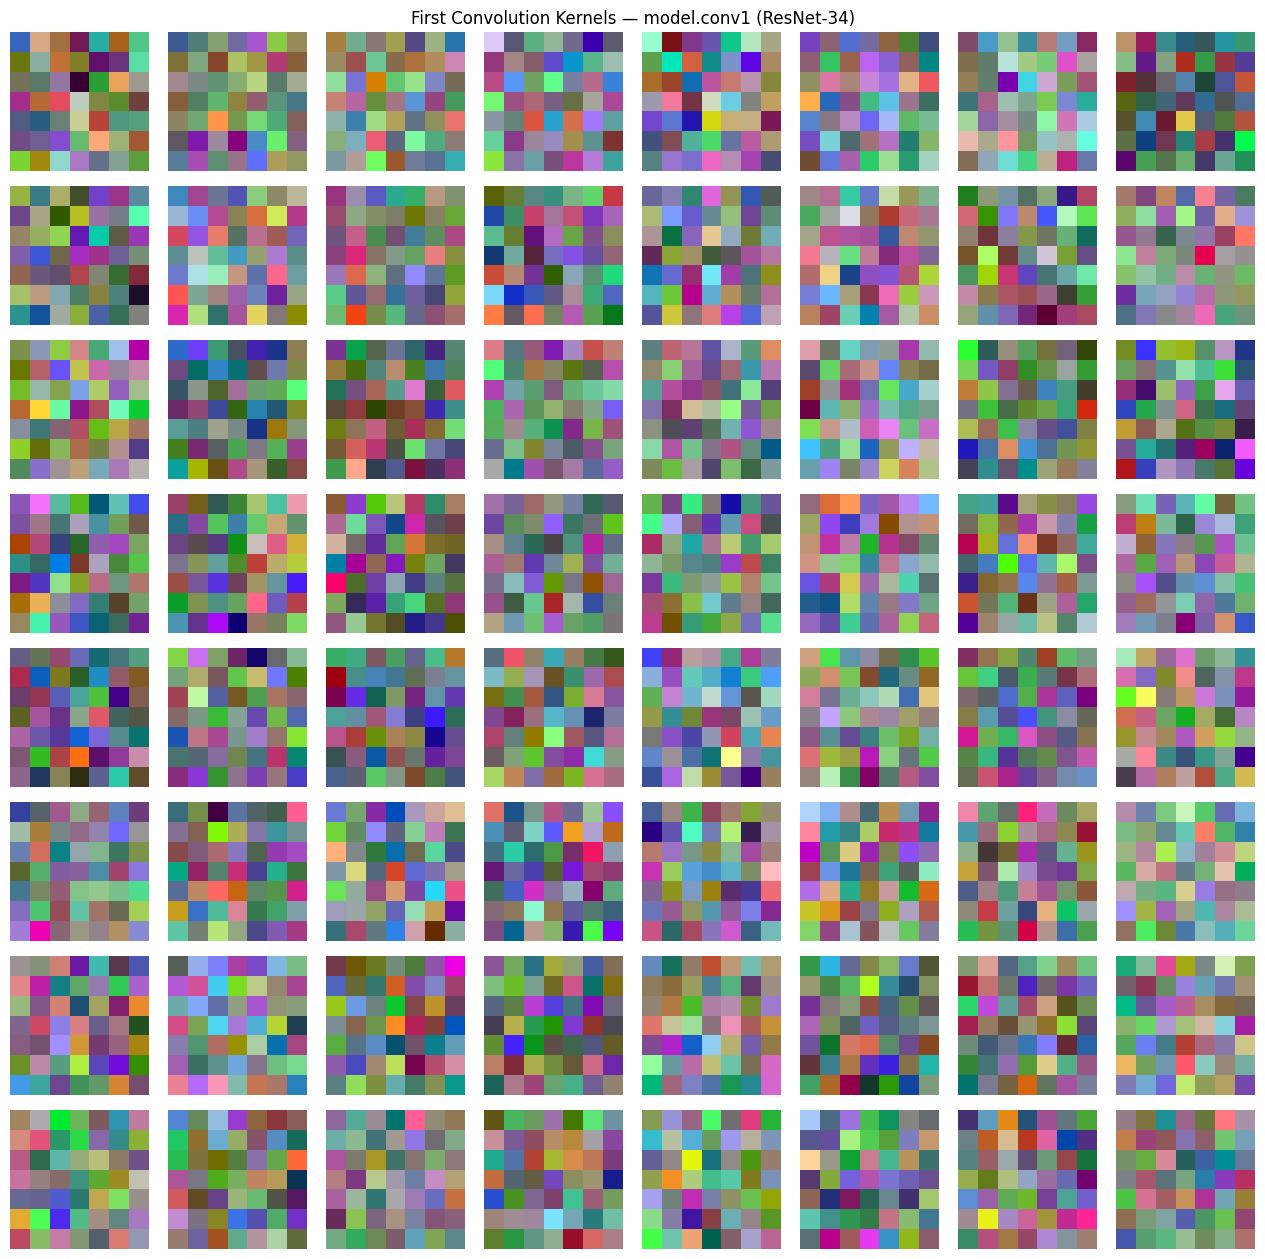

In [26]:
cols, rows = 8, 8
plt.figure(figsize=(cols*1.6, rows*1.6))
for i in range(min(64, w_norm.size(0))):
    plt.subplot(rows, cols, i+1)
    filt = np.transpose(w_norm[i].numpy(), (1,2,0))  
    filt = np.clip(filt, 0, 1)
    plt.imshow(filt)
    plt.axis("off")
plt.suptitle("First Convolution Kernels — model.conv1 (ResNet-34)")
plt.tight_layout()
plt.show()

**Analysis:**
• Many filters resemble oriented edge detectors (light/dark transitions at different angles).
• Some filters emphasize specific color contrasts (e.g., red-green or blue-yellow), useful for flowers.
• These primitive features combine across layers to form textures and shapes in deeper blocks.

## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap | each 50% |
| 2 | pranayla & vpampulap | each 50% |
| 3 | pranayla & vpampulap | each 50% |


